# 미니프로젝트: 머신러닝 프로세스 (Vibe Coding)

#### <목표>
오늘 배운 머신러닝 프로세스를 **제조 데이터셋**에 적용해 봅니다.

**Cursor AI**를 활용하여 각 단계의 코드를 직접 생성하고 실행해 보세요.

#### <데이터셋 소개>
- AI4I 2020 Predictive Maintenance (예지 정비)
- 10,000개 제조 장비 운전 데이터

| 변수명 | 설명 |
|:---:|:---|
| Type | 제품 품질 등급 (L: Low, M: Medium, H: High) |
| Air temperature | 공기 온도 [K] |
| Process temperature | 공정 온도 [K] |
| Rotational speed | 회전 속도 [rpm] |
| Torque | 토크 [Nm] |
| Tool wear | 공구 마모 시간 [min] |
| Machine failure | 기계 고장 여부 (0: 정상, 1: 고장) |
| TWF, HDF, PWF, OSF, RNF | 고장 유형별 발생 여부 |

#### <실습 태스크>
| 태스크 | 타겟 변수 | 설명 |
|:---:|:---:|:---|
| 회귀 | `Torque` | 운전 조건(온도, 회전속도, 공구마모 등)으로 토크 예측 |
| 분류 | `Machine failure` | 운전 조건으로 기계 고장 여부 예측 |

1. 각 섹션의 **과제**를 읽고, 어떤 고민/결정이 필요한지 먼저 생각해 봅니다.
2. 빈 코드 셀을 클릭한 후 Cursor AI 채팅창을 엽니다.
3. 막막한 부분은 AI와 상의해서 방법을 정하고, 그 방법으로 프롬프트를 작성합니다.
4. 생성된 코드를 실행하고 결과를 확인합니다.

## 0) 분석 준비

- `dataset/day1_miniproject.csv` 파일을 사용하기
- 하나의 원본 데이터에서 태스크별로 데이터프레임을 분리하기
    - **회귀용 (Regression):** 타겟 = `Torque`, 입력 = Type, Air temperature, Process temperature, Rotational speed, Tool wear
    - **분류용 (Classification):** 타겟 = `Machine failure`, 입력 = Type, Air temperature, Process temperature, Rotational speed, Torque, Tool wear

**[과제]** 써니는 오늘부로 제조 설비 운전 데이터를 분석하게 되었습니다. 분석에 필요한 라이브러리를 불러오고, 회귀용/분류용 데이터셋을 각각 어떻게 구성해야 할지 AI와 상의해서 코드를 작성하세요.

In [2]:
# ===== 1. 필요한 라이브러리 불러오기 =====
import pandas as pd   # 데이터프레임(표 형태 데이터) 처리를 위한 라이브러리
import numpy as np    # 수치 연산(배열, 통계 계산 등)을 위한 라이브러리

# 시각화 라이브러리 (이후 EDA 단계에서 사용 예정이라 미리 불러둠)
import matplotlib.pyplot as plt
import seaborn as sns

# ===== 2. 원본 데이터 불러오기 =====
# 제조 설비 운전 데이터를 하나의 데이터프레임으로 읽어옴
df = pd.read_csv("dataset/day1_miniproject.csv")

# 데이터가 잘 불러와졌는지 확인 (행 개수, 컬럼 목록, 상위 5개 행)
print(df.shape)
df.head()

# ===== 3. 회귀용 데이터셋 구성 =====
# 타겟(y): Torque (토크, 연속적인 숫자 값 -> 회귀 문제)
# 입력(X): Type, Air temperature, Process temperature, Rotational speed, Tool wear
#   -> Torque를 예측하는 데 사용할 운전 조건 변수들만 선택
reg_features = ["Type", "Air temperature", "Process temperature", "Rotational speed", "Tool wear"]
reg_target = "Torque"

X_reg = df[reg_features]   # 회귀용 입력 데이터
y_reg = df[reg_target]     # 회귀용 타겟(정답) 데이터

# 이후 분석에서 함께 다루기 편하도록 입력+타겟을 합친 회귀용 데이터프레임도 준비
df_reg = df[reg_features + [reg_target]]

# ===== 4. 분류용 데이터셋 구성 =====
# 타겟(y): Machine failure (0: 정상, 1: 고장 -> 두 개의 범주 -> 분류 문제)
# 입력(X): Type, Air temperature, Process temperature, Rotational speed, Torque, Tool wear
#   -> 회귀용과 달리 Torque도 입력 변수로 포함됨에 유의
clf_features = ["Type", "Air temperature", "Process temperature", "Rotational speed", "Torque", "Tool wear"]
clf_target = "Machine failure"

X_clf = df[clf_features]   # 분류용 입력 데이터
y_clf = df[clf_target]     # 분류용 타겟(정답) 데이터

# 이후 분석에서 함께 다루기 편하도록 입력+타겟을 합친 분류용 데이터프레임도 준비
df_clf = df[clf_features + [clf_target]]

# ===== 5. 결과 확인 =====
# 회귀용 데이터셋 확인
print("회귀용 데이터셋 shape:", df_reg.shape)
display(df_reg.head())

# 분류용 데이터셋 확인
print("분류용 데이터셋 shape:", df_clf.shape)
display(df_clf.head())

(10000, 12)
회귀용 데이터셋 shape: (10000, 6)


,Type,Air temperature,Process temperature,Rotational speed,Tool wear,Torque
0,M,298.1,308.6,1551,0,42.8
1,L,298.2,308.7,1408,3,46.3
2,L,298.1,308.5,1498,5,49.4
3,L,298.2,308.6,1433,7,39.5
4,L,298.2,308.7,1408,9,40.0


분류용 데이터셋 shape: (10000, 7)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
0,M,298.1,308.6,1551,42.8,0,0
1,L,298.2,308.7,1408,46.3,3,0
2,L,298.1,308.5,1498,49.4,5,0
3,L,298.2,308.6,1433,39.5,7,0
4,L,298.2,308.7,1408,40.0,9,0


In [5]:
df.head()

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


---
## 1) 데이터 탐색 (EDA)

### 1-1) Value 기반 탐색

**[과제]** 써니는 본격적인 분석에 앞서 데이터가 어떻게 생겼는지 먼저 파악하고 싶습니다. AI와 어떠한 데이터 정보를 확인하면 좋을지 상의해보고 관련 정보를 확인해보세요.

In [6]:
df_reg.describe(include='all')

,Type,Air temperature,Process temperature,Rotational speed,Tool wear,Torque
count,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
unique,3,NaN,NaN,NaN,NaN,NaN
top,L,NaN,NaN,NaN,NaN,NaN
freq,6000,NaN,NaN,NaN,NaN,NaN
mean,NaN,300.004930,310.005560,1538.776100,107.951000,39.986910
std,NaN,2.000259,1.483734,179.284096,63.654147,9.968934
min,NaN,295.300000,305.700000,1168.000000,0.000000,3.800000
25%,NaN,298.300000,308.800000,1423.000000,53.000000,33.200000
50%,NaN,300.100000,310.100000,1503.000000,108.000000,40.100000
75%,NaN,301.500000,311.100000,1612.000000,162.000000,46.800000


In [7]:
df_clf.describe(include='all')

,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
count,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
unique,3,NaN,NaN,NaN,NaN,NaN,NaN
top,L,NaN,NaN,NaN,NaN,NaN,NaN
freq,6000,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,NaN,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,NaN,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,NaN,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,NaN,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,NaN,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000


### 1-2) Graph 기반 탐색

#### 1-2-1) 단일 변수 분포

**[과제]** 써니는 변수들의 분포가 어떤 모양인지 한눈에 살펴보고 싶습니다. 여러 수치형 변수를 효율적으로 한 번에 볼 수 있는 방법을 AI와 상의해서 시각화해 보세요.

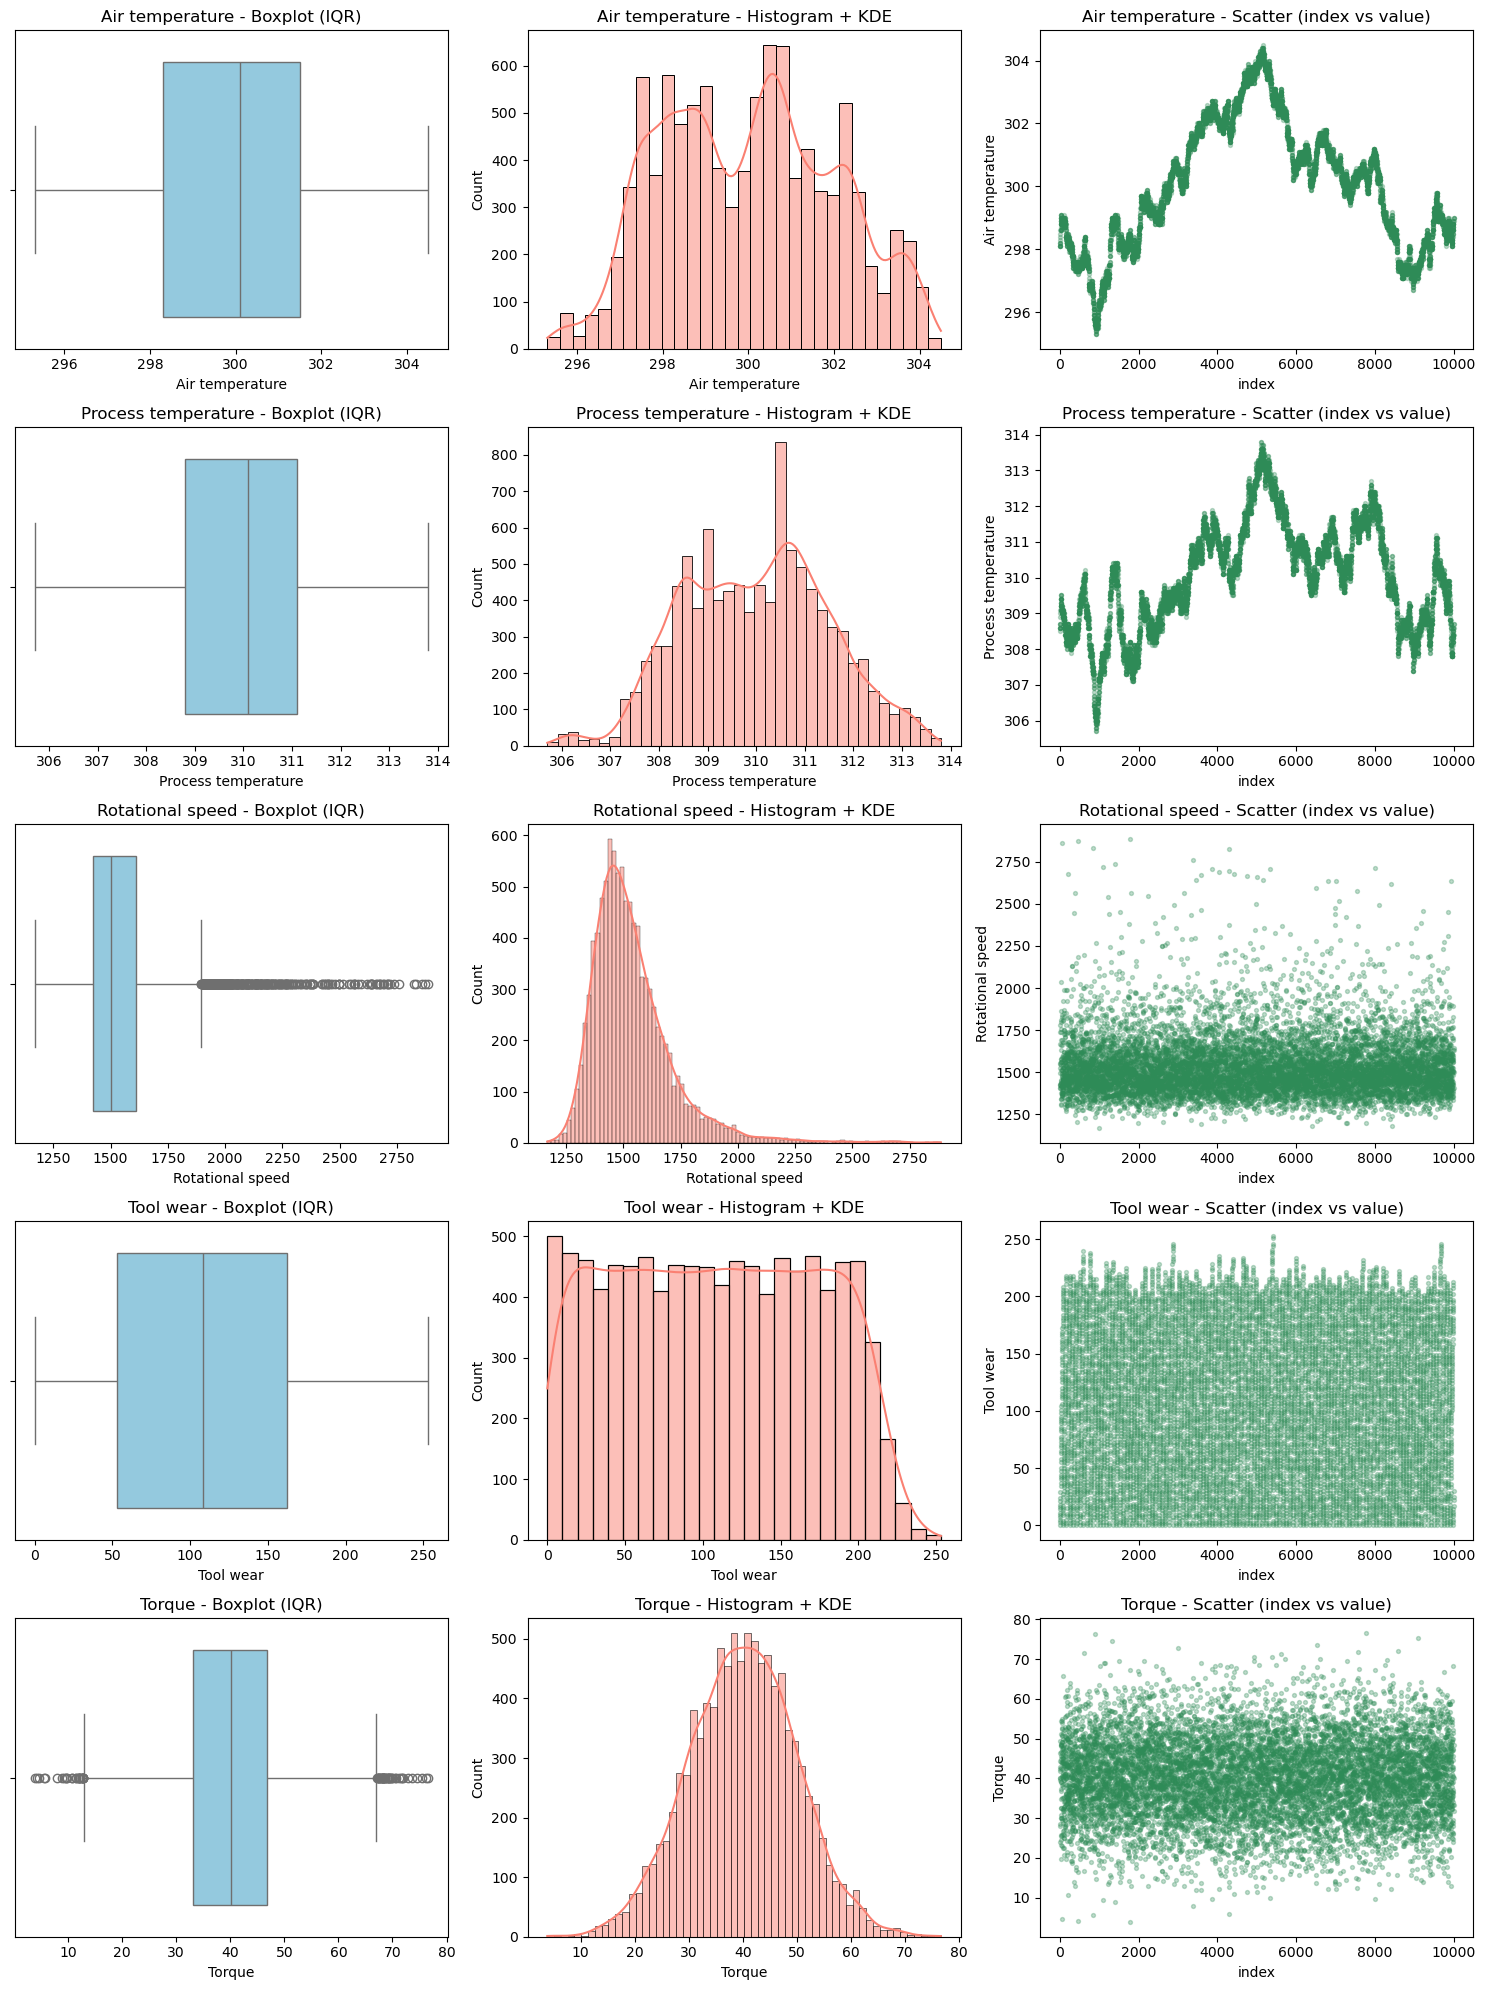

In [8]:
# ===== 회귀용 데이터셋의 수치형 변수 분포 시각화 =====
# 대상 변수: Air temperature, Process temperature, Rotational speed, Tool wear, Torque
num_cols = ["Air temperature", "Process temperature", "Rotational speed", "Tool wear", "Torque"]

# 변수 개수만큼 행(row)을 만들고, 한 행에 boxplot / histogram+kde / scatter(strip) 3개를 배치
n = len(num_cols)
fig, axes = plt.subplots(n, 3, figsize=(15, 4 * n))

for i, col in enumerate(num_cols):
    # 1) Boxplot: 중앙값, IQR(사분위범위), 이상치를 한눈에 확인
    sns.boxplot(x=df_reg[col], ax=axes[i, 0], color="skyblue")
    axes[i, 0].set_title(f"{col} - Boxplot (IQR)")

    # 2) Histogram + KDE: 값이 몰려있는 구간, 좌우 비대칭 여부, 봉우리 개수(모달리티) 확인
    sns.histplot(df_reg[col], kde=True, ax=axes[i, 1], color="salmon")
    axes[i, 1].set_title(f"{col} - Histogram + KDE")

    # 3) Scatter(strip) plot: x축에 데이터 인덱스, y축에 실제 값을 찍어 개별 값의 흩어짐/이상치 확인
    axes[i, 2].scatter(range(len(df_reg)), df_reg[col], alpha=0.3, s=8, color="seagreen")
    axes[i, 2].set_title(f"{col} - Scatter (index vs value)")
    axes[i, 2].set_xlabel("index")
    axes[i, 2].set_ylabel(col)

plt.tight_layout()
plt.show()

**[과제]** 써니는 설비 고장이 실제로 얼마나 자주 발생하는지 궁금합니다. 고장 발생 빈도를 확인할 수 있는 방법을 AI와 함께 찾아보고, 그 결과를 시각화하거나 분석해 보세요. 이 결과가 앞으로의 분석(데이터 분할, 성능 평가 등)에 어떤 영향을 줄 수 있을지도 함께 생각해 보세요.

[클래스별 개수]
Machine failure
0    9661
1     339
Name: count, dtype: int64

[클래스별 비율]
Machine failure
0    96.61%
1     3.39%
Name: proportion, dtype: object


C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\4069655228.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="Machine failure", data=df_clf, palette=["skyblue", "salmon"])
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\4069655228.py:27: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\4069655228.py:27: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\4069655228.py:27: UserWarning: Glyph 44256 (\N{HANGUL SYLLABLE GO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\4069655228.py:27: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s

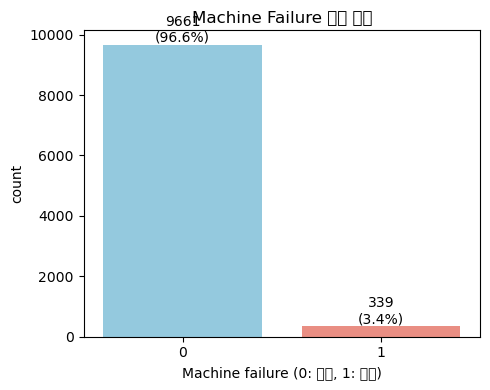


고장(1) 비율: 3.39% -> 클래스 불균형 데이터


In [9]:
# ===== 고장(Machine failure) 발생 빈도 확인 =====

# 1) 클래스별 개수와 비율 확인
failure_counts = df_clf["Machine failure"].value_counts()             # 0/1 각각 몇 개인지
failure_ratio = df_clf["Machine failure"].value_counts(normalize=True)  # 0/1 각각 비율(%)

print("[클래스별 개수]")
print(failure_counts)
print("\n[클래스별 비율]")
print((failure_ratio * 100).round(2).astype(str) + "%")

# 2) 막대그래프로 시각화 (막대 위에 개수/비율 텍스트 표시)
plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Machine failure", data=df_clf, palette=["skyblue", "salmon"])
ax.set_title("Machine Failure 발생 빈도")
ax.set_xlabel("Machine failure (0: 정상, 1: 고장)")
ax.set_ylabel("count")

total = len(df_clf)
for p in ax.patches:
    count = int(p.get_height())
    pct = count / total * 100
    ax.annotate(f"{count}\n({pct:.1f}%)",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")

plt.tight_layout()
plt.show()

# 3) 불균형 정도 확인
# -> 고장(1)이 전체의 3~4% 수준이면 클래스 불균형이 심한 데이터라는 뜻!
# -> 이후 데이터 분할 시에는 stratify=y_clf 로 층화추출을 해서 train/test에
#    0과 1 비율이 원본과 동일하게 유지되도록 해야 한다.
# -> 성능 평가 시에는 accuracy만으로는 왜곡될 수 있으므로(전부 0으로만 예측해도
#    정확도가 높게 나옴), precision/recall/f1-score/ROC-AUC 등을 함께 봐야 한다.
print(f"\n고장(1) 비율: {failure_ratio[1] * 100:.2f}% -> 클래스 불균형 데이터")

**[과제]** 써니는 설비가 고장 났을 때와 정상일 때 변수들의 분포가 어떻게 다른지 비교하고 싶습니다. 어떻게 비교하면 차이가 잘 드러날지 AI와 상의해서 방법을 정하고 직접 시각화해 보세요.

C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\2468503814.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_clf, x="Machine failure", y=col, ax=axes[i, 1],
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\2468503814.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_clf, x="Machine failure", y=col, ax=axes[i, 1],
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\2468503814.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_clf, x="Machine failure", y=col, ax=axes[i, 1],
C:\Users\Admin\AppData\Local

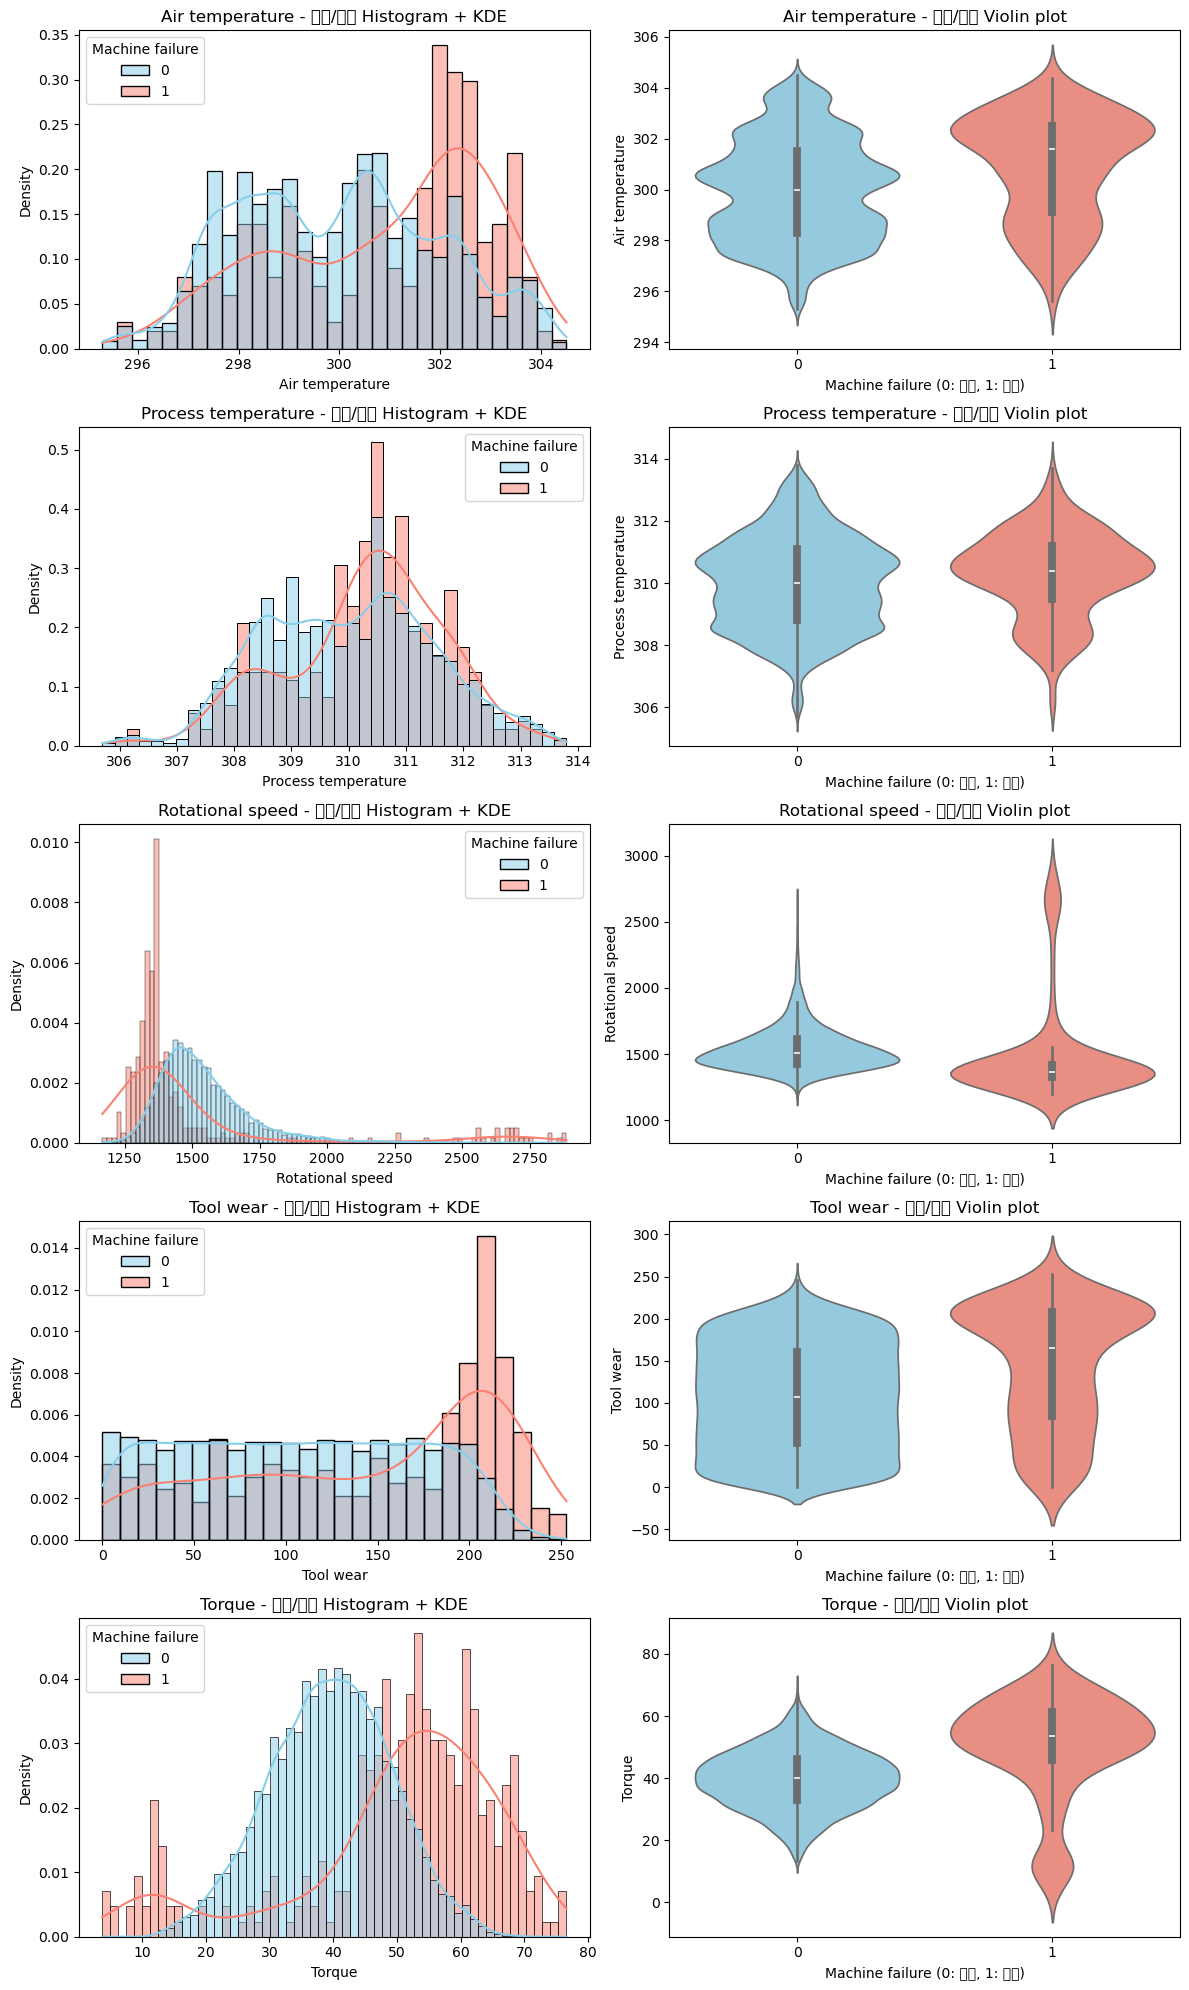

In [10]:
# ===== 고장(Machine failure) 여부에 따른 변수별 분포 비교 =====
# 정상(0)과 고장(1) 그룹을 겹쳐 그려서, 두 그룹의 분포가 얼마나 다른지 확인
# - Histogram + KDE: 값이 몰려있는 구간 자체가 다른지 확인
# - Violin plot: 분포 모양(폭, 중앙값, 퍼짐 정도)을 클래스별로 나란히 비교
num_cols = ["Air temperature", "Process temperature", "Rotational speed", "Tool wear", "Torque"]

n = len(num_cols)
fig, axes = plt.subplots(n, 2, figsize=(12, 4 * n))

for i, col in enumerate(num_cols):
    # 1) Histogram + KDE: hue로 정상/고장 그룹을 겹쳐서 그려 분포 위치/모양 차이를 확인
    sns.histplot(data=df_clf, x=col, hue="Machine failure", kde=True,
                 stat="density", common_norm=False, ax=axes[i, 0],
                 palette=["skyblue", "salmon"])
    axes[i, 0].set_title(f"{col} - 정상/고장 Histogram + KDE")

    # 2) Violin plot: x축에 고장 여부(0/1), y축에 변수 값을 두어
    #    각 그룹의 분포 모양(중앙값, 퍼짐, 좌우 비대칭)을 한 번에 비교
    sns.violinplot(data=df_clf, x="Machine failure", y=col, ax=axes[i, 1],
                   palette=["skyblue", "salmon"])
    axes[i, 1].set_title(f"{col} - 정상/고장 Violin plot")
    axes[i, 1].set_xlabel("Machine failure (0: 정상, 1: 고장)")

plt.tight_layout()
plt.show()

#### 1-2-2) 변수 간 관계

**[과제]** 써니는 변수들 간에 강하게 얽혀 있는 관계(다중공선성 후보)가 있는지 한눈에 살펴보고 싶습니다. 전체 변수 간 관계를 효율적으로 볼 수 있는 방법을 AI와 상의해서 시각화해 보세요.

In [ ]:
# ===== 전체 변수 간 상관관계 히트맵 =====
# 수치형 변수들 간의 상관계수를 한 번에 확인 (범주형 Type은 제외)
num_cols = ["Air temperature", "Process temperature", "Rotational speed", "Tool wear", "Torque"]
corr = df[num_cols].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("변수 간 상관관계 히트맵")
plt.tight_layout()
plt.show()

# -> 상관계수가 1 또는 -1에 가까운 변수쌍이 있다면 다중공선성 후보로 의심해볼 수 있음
#    (다음 단계인 VIF 분석에서 실제로 다중공선성이 있는지 좀 더 정확히 확인)

**[과제]** 써니는 히트맵으로 상관관계가 높은 변수쌍은 찾았지만, 단순한 상관계수만으로 변수들이 서로 얽혀 있는 정도를 다 설명할 수 있을지 의문이 듭니다. 상관계수 외에 변수 간의 강한 관계를 파악할 수 있는 다른 방법이 있는지 AI와 함께 찾아보고, 직접 적용해 보세요.

              Variable        R2       VIF
0      Air temperature  0.767657  4.303979
1  Process temperature  0.767593  4.302788
2     Rotational speed  0.765815  4.270132
3               Torque  0.765745  4.268850
4            Tool wear  0.000237  1.000237


C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\2650496198.py:45: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\2650496198.py:45: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\2650496198.py:45: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\2650496198.py:45: UserWarning: Glyph 45796 (\N{HANGUL SYLLABLE DA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\2650496198.py:45: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_10712\2650496198.py:45: UserWarning: Glyph 44277 (\N{HANGUL SYLLABLE GONG}) missing

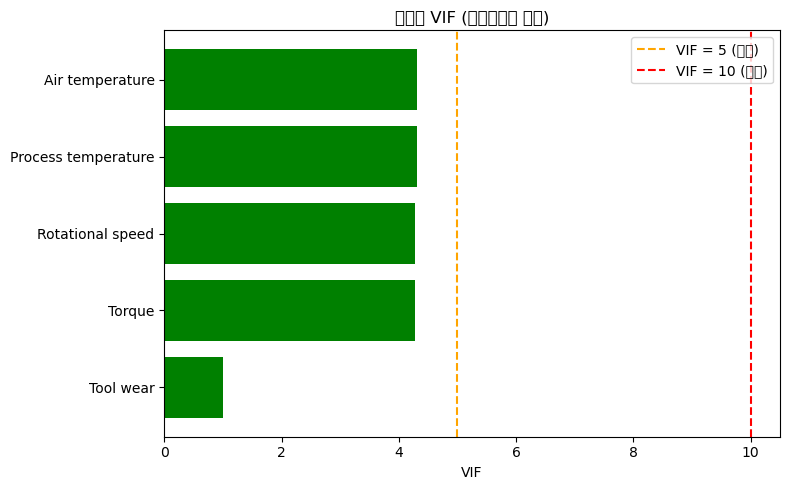

In [12]:
# ===== 다중공선성(Multicollinearity) 진단: R² & VIF =====
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# 대상: 수치형 변수 5개 (범주형 Type은 제외)
num_cols = ["Air temperature", "Process temperature", "Rotational speed", "Tool wear", "Torque"]
X_num = df[num_cols]

# VIF 계산 시 절편(intercept)을 위한 상수항이 필요함
X_const = add_constant(X_num)

vif_data = []
for col in num_cols:
    # variance_inflation_factor: 해당 변수를 나머지 변수들로 회귀했을 때의 VIF를 계산
    # (VIF = 1 / (1 - R²) 이므로, 역으로 VIF에서 R²도 구할 수 있음)
    col_idx = X_const.columns.get_loc(col)
    vif = variance_inflation_factor(X_const.values, col_idx)
    r2 = 1 - 1 / vif
    vif_data.append({"Variable": col, "R2": r2, "VIF": vif})

# VIF가 큰 순서대로 정렬해서 표로 확인 (VIF가 클수록 다른 변수들로 설명이 잘 되는, 즉 다중공선성이 강한 변수)
vif_df = pd.DataFrame(vif_data).sort_values("VIF", ascending=False).reset_index(drop=True)
print(vif_df)

# ===== VIF 시각화 (가로 막대그래프 + 기준선) =====
# 일반적인 판단 기준: VIF > 10 (심각), 5 < VIF <= 10 (주의), VIF <= 5 (문제 없음)
def vif_color(v):
    if v > 10:
        return "red"
    elif v > 5:
        return "orange"
    else:
        return "green"

colors = vif_df["VIF"].apply(vif_color)

plt.figure(figsize=(8, 5))
plt.barh(vif_df["Variable"], vif_df["VIF"], color=colors)
plt.axvline(5, color="orange", linestyle="--", label="VIF = 5 (주의)")
plt.axvline(10, color="red", linestyle="--", label="VIF = 10 (심각)")
plt.xlabel("VIF")
plt.title("변수별 VIF (다중공선성 진단)")
plt.legend()
plt.gca().invert_yaxis()  # VIF가 큰 변수가 위쪽에 오도록 정렬
plt.tight_layout()
plt.show()

---
## 2) 데이터 전처리

### 2-1) 불필요한 변수 제거 및 결측치 확인

**[과제]** 써니는 모델에 넣기 전에 분석에 도움이 안 되거나, 오히려 결과를 왜곡시킬 수 있는 변수가 있는지 점검하려고 합니다. 어떤 변수를 빼야 하는지, 그 이유는 무엇인지 AI와 상의해서 정리하고 제거해 보세요.

### 2-2) 데이터 분할

**[과제]** 써니는 학습/테스트 데이터를 나누려고 합니다. 회귀용과 분류용 각각에 어떤 분할 방법과 기준이 적합할지 AI와 상의해서 정하고, 그 기준대로 직접 나눠 보세요.

### 2-3) 변수 스케일링

**[과제]** 써니는 수치형 변수들의 스케일이 제각각이라 모델 학습 전에 맞춰주고 싶습니다. 변수들의 분포를 보면서 어떤 스케일링 기법이 적합할지 AI와 상의해서 정하고 적용해 보세요.

**[과제]** 써니는 `Type` 변수를 모델에 넣으려면 숫자로 바꿔야 한다는 건 알고 있지만, 원-핫 인코딩과 라벨 인코딩 중 어느 쪽이 맞을지 고민입니다. 어떤 기준으로 선택해야 할지 AI와 상의해서 정하고 적용해 보세요.

---
## 3) 모델링

### 3-1) 모델 생성 및 학습

**[과제]** 써니는 여러 모델의 성능을 한 번에 비교해보고 싶습니다. 회귀와 분류 각각 어떤 모델을 후보로 둘지, 매번 코드를 새로 짜지 않고 효율적으로 비교할 방법은 무엇일지 AI와 상의해서 코드를 작성해 보세요.

### 3-2) 테스트 데이터 예측

**[과제]** 써니는 앞서 학습시킨 회귀 및 분류 모델들로 테스트 데이터에 대한 예측을 수행하려고 합니다. 모든 모델의 예측 결과를 한 번에 뽑을 수 있도록 AI와 함께 코드를 작성해 보세요.

### 3-3) 성능 평가

**[과제]** 써니는 모델 성능을 비교하려고 하는데, 회귀와 분류 각각 사용할 수 있는 지표가 다양해서 무엇을 기준으로 봐야 할지 고민입니다. 적절한 지표를 AI와 상의해서 정하고, 그 기준으로 가장 좋은 모델을 선택해 보세요.

---
## 4) 모델 고도화

**[과제]** 써니는 가장 성능이 좋았던 모델을 더 끌어올리고 싶습니다. 어떤 하이퍼파라미터를 어느 범위까지 탐색하면 좋을지 AI와 상의해서 정하고, 그 기준으로 성능을 높여 보세요.

---
## 5) 모델 결과 분석

**[과제]** 써니는 최종적으로 어떤 운전 조건이 토크와 고장에 가장 큰 영향을 미치는지 정리해서 보고하려고 합니다. 회귀와 분류 각각에서 성능이 가장 좋았던 모델의 변수 중요도를 구하고 시각화하는 방법을 AI와 함께 알아본 뒤, 그 결과로부터 인사이트를 도출해 보세요.